---
title: "3.3.d Escenarios: un río que se aleja"
short_title: "d. Escenarios"
subtitle: "Tendencia del brazo colombiano y efecto de un ciclo hidrológico más extremo sobre las orillas"
description: "Escenarios de evolución del cauce del Amazonas frente a Leticia y su interacción con el cambio climático."
keywords: [erosión, sedimentación, escenarios, navegabilidad, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/33_erosion/d_escenarios.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

La dinámica del cauce responde sobre todo a procesos geomorfológicos y al aporte de sedimentos de los Andes, que
también dependen del clima y del uso del suelo en la cuenca alta. El cambio climático la modula de dos formas:
**crecientes más altas** movilizan más sedimento y erosionan más, y **vaciantes más profundas** dejan expuestos
barrancos saturados que colapsan al bajar el agua.

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import aoi, espacial, exposicion, fuentes, viz
from leticia.config import parametros

pe = parametros()["erosion"]
urbana = aoi.area_urbana()
PIX_HA = (0.0003 * 111320) ** 2 * np.cos(np.radians(4.2)) / 1e4   # área de un píxel de 0,0003° en ha


def agua_anio(anio):
    ds = espacial.compuesto_landsat(anio, pe["meses_aguas_bajas"], ventana_anios=1 if anio < 2000 else 0)
    return (espacial.mndwi(ds) > pe["umbral_mndwi"]).rio.write_crs(4326), ds.attrs["escenas"]

## 1. Tendencia del agua en aguas bajas frente a Leticia

,agua_ha,nivel_m
año,,
1987,365.50,8.50
2001,346.70,10.70
2013,360.10,10.30
2024,245.60,4.70


Tendencia del agua frente a la ciudad descontando el efecto del nivel: **-1.5 ha por año** (con solo 4 años es un indicio, no una estimación robusta).

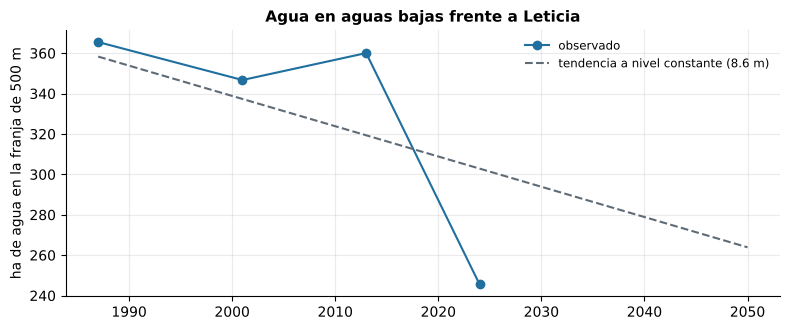

In [3]:
frente = urbana.buffer(500).difference(urbana.geometry.iloc[0]).to_crs(4326)
nivel = fuentes.nivel_rio()
filas = []
for anio in pe["anios_comparacion"]:
    m, _ = agua_anio(anio)
    v = m.astype(float).rio.clip(frente.geometry, drop=True)
    ventana = [anio - 1, anio, anio + 1] if anio < 2000 else [anio]   # misma ventana de años que el compuesto Landsat
    filas.append({"año": anio, "agua_ha": float(np.nansum(v.values)) * PIX_HA,
                  "nivel_m": nivel[nivel.index.year.isin(ventana) & nivel.index.month.isin(pe["meses_aguas_bajas"])].mean() / 100})
df = pd.DataFrame(filas).set_index("año")
# regresión: agua ~ año + nivel, para separar la tendencia del cauce del efecto del nivel del río
X = np.column_stack([np.ones(len(df)), df.index.values, df["nivel_m"].fillna(df["nivel_m"].mean()).values])
coef, *_ = np.linalg.lstsq(X, df["agua_ha"].values, rcond=None)
display(df.round(1))
display(Markdown(f"Tendencia del agua frente a la ciudad descontando el efecto del nivel: **{coef[1]:+.1f} ha por año** "
                 f"(con solo {len(df)} años es un indicio, no una estimación robusta)."))
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(df.index, df["agua_ha"], "o-", color=viz.AZUL_RIO, label="observado")
futuro = np.arange(df.index.min(), 2051)
nivel_ref = df["nivel_m"].mean()
ax.plot(futuro, coef[0] + coef[1] * futuro + coef[2] * nivel_ref, "--", color=viz.GRIS, label=f"tendencia a nivel constante ({nivel_ref:.1f} m)")
ax.set_ylabel("ha de agua en la franja de 500 m")
ax.set_title("Agua en aguas bajas frente a Leticia")
ax.legend()
fig.tight_layout()

:::{warning} Una extrapolación, no un pronóstico
Con cuatro fechas la tendencia es solo indicativa. Según la Armada Nacional, un modelo de 2018 proyectaba que
hacia 2030 Leticia solo tendría acceso al río en aguas altas si no se intervenía el cauce
[@rtvc2025sedimentacion]. En 2025 Colombia y Perú acordaron estudios técnicos conjuntos y un plan de monitoreo del
sector Atacuari–Leticia [@forbes2025navegabilidad]. Un monitoreo anual con Landsat y Sentinel-2, como el de este
cuaderno, es una forma barata de seguir esa evolución.
:::

## 2. Un ciclo hidrológico más extremo

Mayores descensos en 30 días: 1997 (7.7 m), 2026 (7.5 m), 2018 (7.1 m), 1996 (6.3 m), 2011 (6.2 m).

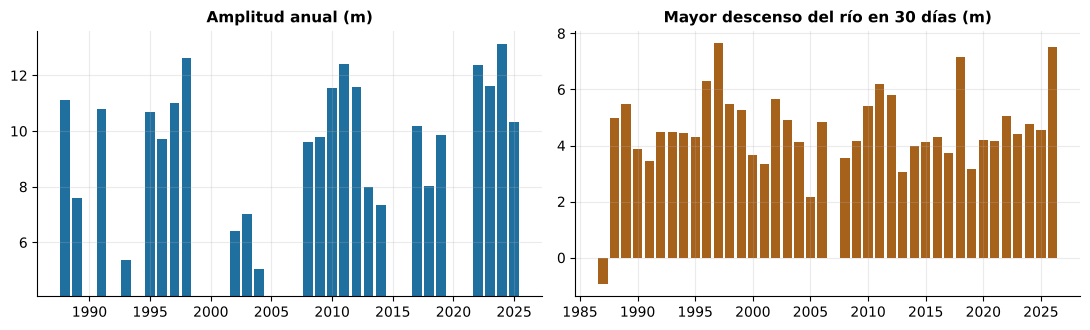

In [4]:
from leticia import hidro
nv = hidro.limpiar_nivel(nivel)
bajada = nv.diff(30).groupby(nv.index.year).min() / 100    # mayor descenso en 30 días de cada año
amp = (hidro.extremos_anuales(nv, "max")["valor"] - hidro.extremos_anuales(nv, "min")["valor"]).dropna() / 100
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(amp.index, amp, color=viz.AZUL_RIO)
ax[0].set_ylim(amp.min() - 1, amp.max() + 0.5)
ax[0].set_title("Amplitud anual (m)")
b2 = bajada.dropna()
ax[1].bar(b2.index, -b2, color=viz.TIERRA)
ax[1].set_title("Mayor descenso del río en 30 días (m)")
fig.tight_layout()
display(Markdown(f"Mayores descensos en 30 días: " + ", ".join(f"{a} ({-v:.1f} m)" for a, v in b2.nsmallest(5).items()) + "."))

**Lectura.** Las bajadas rápidas del río son las más peligrosas para las orillas: el barranco saturado pierde
el soporte del agua. Si la amplitud entre crecientes y vaciantes sigue aumentando, como en Manaos
[@marengo2024spa], la erosión de orillas tenderá a intensificarse. Las medidas recomendadas son el **monitoreo
de orillas** en los barrios ribereños, el control de construcciones nuevas en la franja activa y estudios
geotécnicos antes de cualquier obra de protección.